# LLM / Transformer 핵심 메커니즘 실습 노트북

핵심 메커니즘을 무거운 모델 학습 없이, **numpy로 직접 조립**하면서 눈으로 확인하는 실습입니다.

실제 LLM은 수천억 개의 파라미터를 "학습(training)"하지만, 이 노트북에서는
학습이 끝난 뒤의 **연산 구조(forward pass)** 자체에 집중합니다.
("어떻게 학습되는가"보다 "어떤 계산을 하는가"를 체험하는 것이 목표입니다.)

## 목차
- **Part 0.** 환경 준비
- **Part 1.** (워밍업) 오토인코더 & Seq2Seq — 시퀀스를 벡터로 압축한다는 것
- **Part 2.** Scaled Dot-Product Attention 밑바닥부터 구현하기
- **Part 3.** Multi-Head Attention — 여러 시각으로 동시에 보기
- **Part 4.** Positional Encoding — 순서 정보를 벡터에 새겨넣기
- **Part 5.** Causal Masking — GPT처럼 미래를 못 보게 만들기
- **Part 6.** 미니 트랜스포머 블록 조립하기
- **Part 7.** 서브워드 토크나이저 미니 구현 (BPE)
- **Part 8.** Vision Transformer — 이미지를 "문장"으로 바꾸기


---
## Part 0. 환경 준비


In [13]:
# 처음 실행 시 주석을 풀고 실행하세요 (이미 설치되어 있다면 건너뛰어도 됩니다)
# !pip install numpy matplotlib scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['axes.unicode_minus'] = False

np.random.seed(42)
print("환경 준비 완료 ")


환경 준비 완료 


---
# Part 1. (워밍업) 오토인코더 & Seq2Seq

트랜스포머로 들어가기 전에, 강의자료 앞부분의 핵심 아이디어 두 가지를 짧게 체험합니다.
둘 다 결국 "**정보를 압축해서 벡터 하나로 표현한다**"는 공통점이 있습니다.


### 1.1 오토인코더: 압축하고 복원하기

슬라이드의 "인코더-잠재공간-디코더" 구조를 sklearn의 작은 신경망(MLP)으로 체험합니다.
64차원 손글씨 숫자 이미지를 **8차원**으로 압축했다가 다시 복원해봅니다.


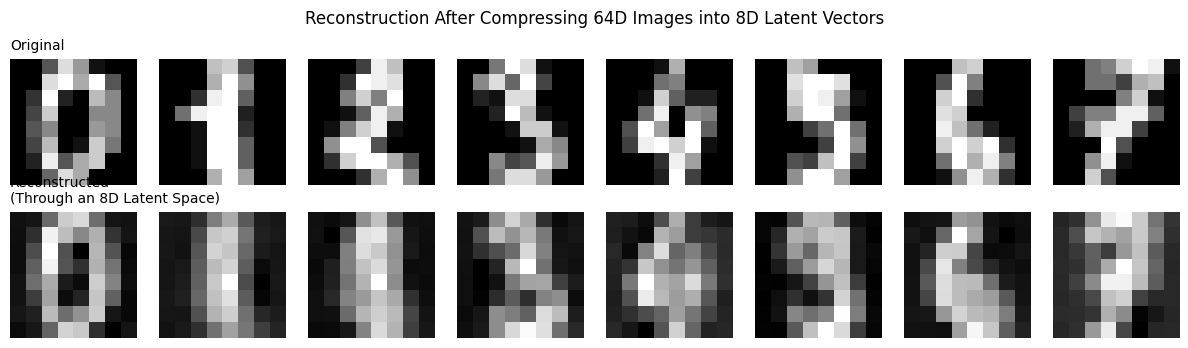

 8개의 숫자만으로도 이미지의 '본질'이 어느 정도 복원되는 것을 확인할 수 있습니다.
   이것이 '압축된 표현(임베딩)'의 힘입니다.


In [14]:
from sklearn.datasets import load_digits
from sklearn.neural_network import MLPRegressor

digits = load_digits()
X = digits.data / 16.0  # 0~1로 정규화

# 인코더(64->8)와 디코더(8->64)를 한 번에 학습하는 오토인코더
# hidden_layer_sizes의 가운데 값(8)이 '잠재 공간(latent space)'의 차원
autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 8, 32),
    max_iter=800,
    random_state=42,
    alpha=1e-4
)
autoencoder.fit(X, X)  # 입력과 출력이 똑같은 것을 목표로 학습! (자기 자신을 복원)

reconstructed = autoencoder.predict(X)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))

for i in range(8):
    axes[0, i].imshow(X[i].reshape(8, 8), cmap='gray')
    axes[0, i].axis('off')

    axes[1, i].imshow(reconstructed[i].reshape(8, 8), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_title('Original', loc='left', fontsize=10)
axes[1, 0].set_title(
    'Reconstructed\n(Through an 8D Latent Space)',
    loc='left',
    fontsize=10
)

plt.suptitle(
    'Reconstruction After Compressing 64D Images '
    'into 8D Latent Vectors'
)

plt.tight_layout()
plt.show()

print(" 8개의 숫자만으로도 이미지의 '본질'이 어느 정도 복원되는 것을 확인할 수 있습니다.")
print("   이것이 '압축된 표현(임베딩)'의 힘입니다.")

### 1.2 Seq2Seq: 시퀀스를 하나의 벡터로 압축하기

슬라이드의 Encoder-Decoder 구조에서, 인코더가 하는 일의 핵심은
**여러 개의 벡터(단어들)를 하나의 고정된 벡터(Context Vector)로 압축하는 것**입니다.

진짜 RNN을 학습시키는 대신, RNN의 핵심 아이디어(이전 상태 + 현재 입력 → 다음 상태)를
아주 단순한 수식으로 직접 구현해서 "시퀀스가 어떻게 벡터 하나로 뭉개지는지" 체험해봅니다.


In [15]:
def simple_rnn_encode(word_vectors, W_hidden=0.6, W_input=0.4):
    # 아주 단순화된 RNN: h_t = W_hidden * h_(t-1) + W_input * x_t
    hidden = np.zeros_like(word_vectors[0])
    history = [hidden.copy()]
    for x_t in word_vectors:
        hidden = np.tanh(W_hidden * hidden + W_input * x_t)
        history.append(hidden.copy())
    return hidden, history  # 최종 hidden = Context Vector

# "I am a student" 라는 문장을 임의의 4차원 벡터들로 표현했다고 가정
sentence = ["I", "am", "a", "student"]
word_vectors = np.random.randn(len(sentence), 4)

context_vector, history = simple_rnn_encode(word_vectors)

print("각 단어를 거치면서 hidden state가 어떻게 변하는지:")
for w, h in zip(["<시작>"] + sentence, history):
    print(f"  {w:8s} -> {np.round(h, 3)}")

print(f"\n최종 Context Vector (문장 전체를 압축한 벡터): {np.round(context_vector, 3)}")
print(" 4개의 단어(4개의 벡터)가 단 하나의 벡터로 압축되었습니다.")
print("   Seq2Seq의 한계는 바로 여기서 나옵니다: 문장이 아무리 길어도 이 벡터 하나에 모든 정보를 욱여넣어야 합니다.")
print("   → 이 한계를 해결하기 위해 등장한 것이 다음 파트의 'Attention'입니다.")


각 단어를 거치면서 hidden state가 어떻게 변하는지:
  <시작>     -> [0. 0. 0. 0.]
  I        -> [ 0.196 -0.055  0.253  0.544]
  am       -> [ 0.024 -0.126  0.655  0.56 ]
  a        -> [-0.172  0.14   0.205  0.149]
  student  -> [-0.006 -0.592 -0.513 -0.135]

최종 Context Vector (문장 전체를 압축한 벡터): [-0.006 -0.592 -0.513 -0.135]
 4개의 단어(4개의 벡터)가 단 하나의 벡터로 압축되었습니다.
   Seq2Seq의 한계는 바로 여기서 나옵니다: 문장이 아무리 길어도 이 벡터 하나에 모든 정보를 욱여넣어야 합니다.
   → 이 한계를 해결하기 위해 등장한 것이 다음 파트의 'Attention'입니다.


---
# Part 2. Scaled Dot-Product Attention 밑바닥부터 구현하기

슬라이드의 "셀프 어텐션 조립 라인" (Step1 매칭 → Step2 스케일링 → Step3 필터링 → Step4 추출)을
그대로 코드 4줄로 구현합니다. 이것이 트랜스포머 전체의 심장입니다.

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$


In [16]:
def softmax(x, axis=-1):
    # 오버플로우 방지를 위해 최댓값을 빼줌 (수치적으로 안전한 softmax)
    x = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=axis, keepdims=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]

    # Step 1. 매칭 (Dot Product): Query와 Key를 내적해서 '연관성 점수' 계산
    scores = Q @ K.T

    # Step 2. 스케일링 (Scaling): 차원이 커질수록 값이 커지는 것을 방지
    scores = scores / np.sqrt(d_k)

    # (선택) 마스킹: 특정 위치를 못 보게 -무한대로 만들기 (Part 5에서 다시 다룸)
    if mask is not None:
        scores = np.where(mask == 0, -1e9, scores)

    # Step 3. 필터링 (Softmax): 점수를 0~1 사이 확률(가중치)로 변환
    attention_weights = softmax(scores, axis=-1)

    # Step 4. 추출 (Multiply V): 가중치와 Value를 곱해서 최종 출력 생성
    output = attention_weights @ V

    return output, attention_weights


### 2.1 장난감 문장으로 직접 확인해보기

"그 동물은 길을 건너지 않았다 왜냐하면 그것은 너무 피곤했기 때문이다"라는
슬라이드의 예문을 흉내내서, **'그것은'이 실제로 '동물'을 주목하는지** 확인해봅니다.

(진짜 학습된 가중치가 아니라 손으로 설계한 임베딩이라 완벽하진 않지만, 메커니즘 자체는 동일합니다.)


In [17]:
tokens = ["그", "동물은", "길을", "건너지", "않았다", "그것은", "피곤했다"]
d_model = 6
np.random.seed(7)

# 각 단어의 임베딩 벡터 (실제로는 학습되지만, 여기선 랜덤 + 의도적 유사성 부여)
embeddings = np.random.randn(len(tokens), d_model) * 0.5
# '동물은'과 '그것은'을 의도적으로 비슷한 벡터로 설정 (실제 학습되면 이런 관계가 자연스럽게 생김)
embeddings[5] = embeddings[1] + np.random.randn(d_model) * 0.1

# Q, K, V로 변환하는 가중치 행렬 (실제로는 학습되지만 여기선 단위행렬에 가까운 랜덤 사용)
Wq = np.eye(d_model) + np.random.randn(d_model, d_model) * 0.05
Wk = np.eye(d_model) + np.random.randn(d_model, d_model) * 0.05
Wv = np.eye(d_model) + np.random.randn(d_model, d_model) * 0.05

Q, K, V = embeddings @ Wq, embeddings @ Wk, embeddings @ Wv
output, weights = scaled_dot_product_attention(Q, K, V)

print("'그것은'(6번째 토큰)이 각 단어에 주는 attention 가중치:")
idx = tokens.index("그것은")
for tok, w in zip(tokens, weights[idx]):
    bar = "█" * int(w * 50)
    print(f"  {tok:6s} {w:.3f} {bar}")


'그것은'(6번째 토큰)이 각 단어에 주는 attention 가중치:
  그      0.133 ██████
  동물은    0.183 █████████
  길을     0.107 █████
  건너지    0.182 █████████
  않았다    0.127 ██████
  그것은    0.182 █████████
  피곤했다   0.086 ████


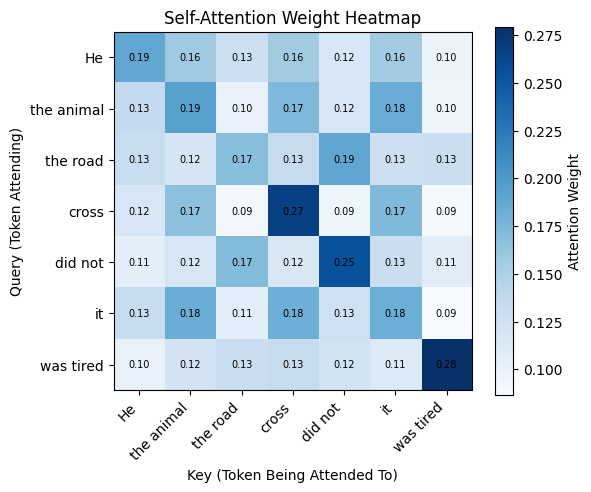

 세로줄(Query)이 가로줄(Key)의 각 단어를 얼마나 '주목'하는지 나타냅니다.


In [18]:
# English labels used only for visualization
token_labels_en = [
    "He",
    "the animal",
    "the road",
    "cross",
    "did not",
    "it",
    "was tired"
]

# Visualize all attention weights as a heatmap
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(weights, cmap='Blues')

ax.set_xticks(range(len(tokens)))
ax.set_xticklabels(token_labels_en, rotation=45, ha='right')

ax.set_yticks(range(len(tokens)))
ax.set_yticklabels(token_labels_en)

ax.set_xlabel('Key (Token Being Attended To)')
ax.set_ylabel('Query (Token Attending)')
ax.set_title('Self-Attention Weight Heatmap')

for i in range(len(tokens)):
    for j in range(len(tokens)):
        ax.text(
            j,
            i,
            f'{weights[i, j]:.2f}',
            ha='center',
            va='center',
            fontsize=7,
            color='white' if weights[i, j] > 0.3 else 'black'
        )

plt.colorbar(im, ax=ax, label='Attention Weight')
plt.tight_layout()
plt.show()

print(" 세로줄(Query)이 가로줄(Key)의 각 단어를 얼마나 '주목'하는지 나타냅니다.")

---
# Part 3. Multi-Head Attention — 여러 시각으로 동시에 보기

슬라이드에서 배운 것처럼, 하나의 Attention만 쓰면 한 가지 관점밖에 못 봅니다.
Multi-Head Attention은 **d_model 차원을 여러 개의 head로 쪼개서**,
각 head가 서로 다른 관점(문법적 관계, 의미적 관계 등)을 학습하게 한 뒤 다시 합칩니다.


In [19]:
def multi_head_attention(X, num_heads, d_model, seed=0, mask=None):
    rng = np.random.default_rng(seed)
    seq_len = X.shape[0]
    assert d_model % num_heads == 0, "d_model은 num_heads로 나누어 떨어져야 합니다"
    d_k = d_model // num_heads

    # Q, K, V, 최종 출력을 위한 가중치 행렬 (실제로는 학습됨)
    Wq = rng.normal(0, 0.1, (d_model, d_model))
    Wk = rng.normal(0, 0.1, (d_model, d_model))
    Wv = rng.normal(0, 0.1, (d_model, d_model))
    Wo = rng.normal(0, 0.1, (d_model, d_model))

    Q, K, V = X @ Wq, X @ Wk, X @ Wv

    # (seq_len, d_model) -> (num_heads, seq_len, d_k) 로 쪼개기
    def split_heads(x):
        return x.reshape(seq_len, num_heads, d_k).transpose(1, 0, 2)

    Qh, Kh, Vh = split_heads(Q), split_heads(K), split_heads(V)

    head_outputs = []
    all_weights = []
    for h in range(num_heads):
        out_h, w_h = scaled_dot_product_attention(Qh[h], Kh[h], Vh[h], mask=mask)
        head_outputs.append(out_h)
        all_weights.append(w_h)

    # 모든 head의 결과를 다시 이어붙이기 (Concat)
    concat = np.concatenate(head_outputs, axis=-1)  # (seq_len, d_model)
    output = concat @ Wo
    return output, np.array(all_weights)  # weights shape: (num_heads, seq_len, seq_len)


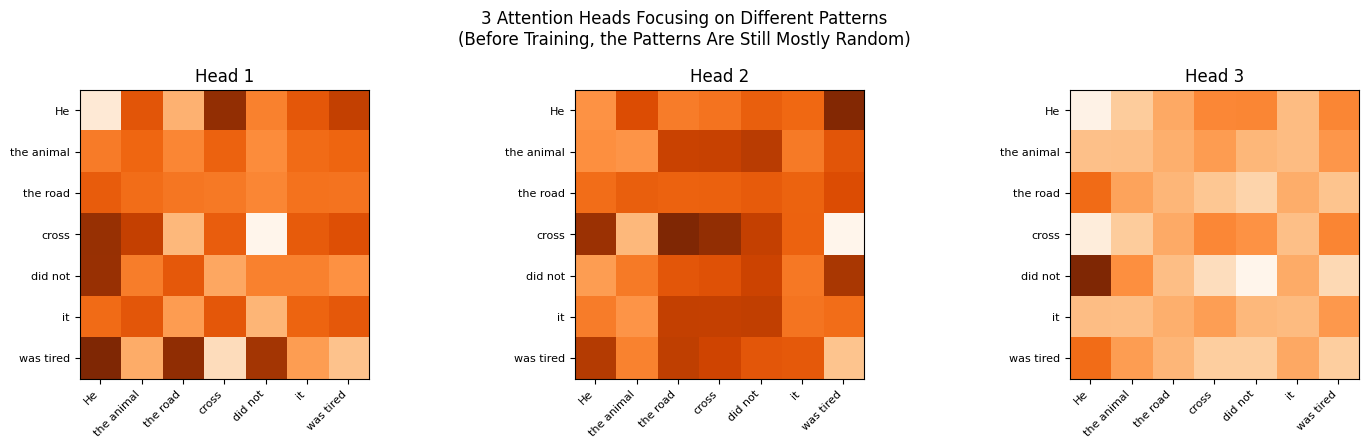

입력 shape: (7, 6)  ->  출력 shape: (7, 6)
 각 head가 서로 다른 (num_heads개의) attention 패턴을 만들어내고, 이를 이어붙여 최종 출력을 만듭니다.
   실제로 학습되면 어떤 head는 '문법 관계'에, 어떤 head는 '의미 관계'에 집중하게 됩니다.


In [20]:
num_heads = 3
out, head_weights = multi_head_attention(
    embeddings,
    num_heads=num_heads,
    d_model=d_model,
    seed=1
)

# English labels used only for visualization
token_labels_en = [
    "He",
    "the animal",
    "the road",
    "cross",
    "did not",
    "it",
    "was tired"
]

fig, axes = plt.subplots(1, num_heads, figsize=(5 * num_heads, 4.5))

for h in range(num_heads):
    ax = axes[h]
    im = ax.imshow(head_weights[h], cmap='Oranges')

    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(
        token_labels_en,
        rotation=45,
        ha='right',
        fontsize=8
    )

    ax.set_yticks(range(len(tokens)))
    ax.set_yticklabels(token_labels_en, fontsize=8)

    ax.set_title(f'Head {h + 1}')

plt.suptitle(
    f'{num_heads} Attention Heads Focusing on Different Patterns\n'
    '(Before Training, the Patterns Are Still Mostly Random)'
)

plt.tight_layout()
plt.show()

print(f"입력 shape: {embeddings.shape}  ->  출력 shape: {out.shape}")
print(" 각 head가 서로 다른 (num_heads개의) attention 패턴을 만들어내고, 이를 이어붙여 최종 출력을 만듭니다.")
print("   실제로 학습되면 어떤 head는 '문법 관계'에, 어떤 head는 '의미 관계'에 집중하게 됩니다.")

---
# Part 4. Positional Encoding — 순서 정보를 벡터에 새겨넣기

Attention은 모든 단어를 "동시에" 처리하기 때문에, 그 자체로는 **순서(어순) 정보가 없습니다.**
슬라이드에서 본 것처럼, 단순히 정수(1,2,3...)를 더하거나 정규화된 값(0~1)을 쓰면 실패합니다.
트랜스포머는 사인/코사인 함수의 조합으로 이 문제를 해결합니다.


### 4.1 왜 단순한 숫자는 실패할까?

슬라이드의 "Positional Failure Matrix"를 직접 재현해봅니다.


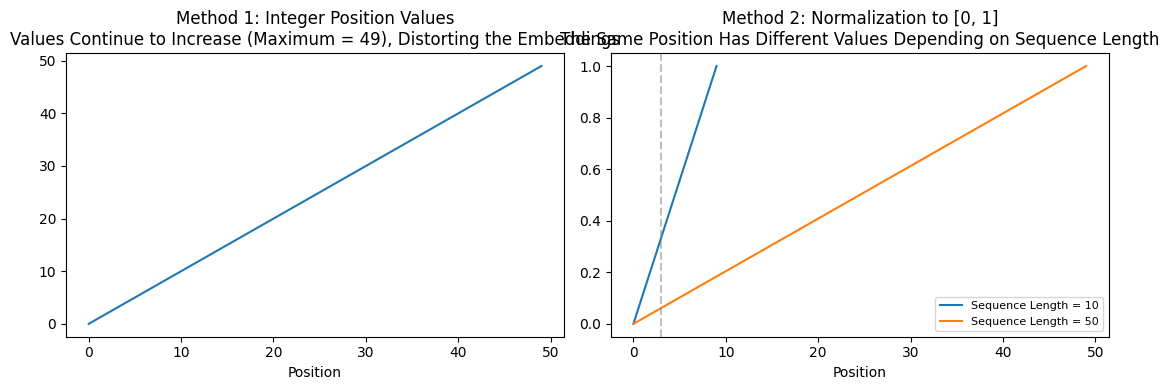

방법2 비교: 문장 길이 10일 때 3번째 위치값=0.333 vs 문장 길이 50일 때 3번째 위치값=0.061
 완전히 다른 값이 나옵니다! 이래서는 '3번째 단어'라는 같은 의미를 일관되게 표현할 수 없습니다.


In [30]:
seq_len = 50
d_model_demo = 4

# 방법 1: 정수를 그대로 부여 (1, 2, 3, ...)
naive_int = np.arange(seq_len).reshape(-1, 1) * np.ones((1, d_model_demo))

# 방법 2: 0~1로 정규화
naive_norm_short = np.linspace(0, 1, 10).reshape(-1, 1) * np.ones((1, d_model_demo))   # 문장 길이 10
naive_norm_long = np.linspace(0, 1, 50).reshape(-1, 1) * np.ones((1, d_model_demo))   # 문장 길이 50

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(naive_int[:, 0])
axes[0].set_title(
    f'Method 1: Integer Position Values\n'
    f'Values Continue to Increase '
    f'(Maximum = {naive_int[:, 0].max():.0f}), Distorting the Embeddings'
)
axes[0].set_xlabel('Position')

axes[1].plot(
    naive_norm_short[:, 0],
    label='Sequence Length = 10'
)
axes[1].plot(
    naive_norm_long[:, 0],
    label='Sequence Length = 50'
)
axes[1].axvline(3, color='gray', linestyle='--', alpha=0.5)
axes[1].set_title(
    'Method 2: Normalization to [0, 1]\n'
    'The Same Position Has Different Values Depending on Sequence Length'
)
axes[1].set_xlabel('Position')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"방법2 비교: 문장 길이 10일 때 3번째 위치값={naive_norm_short[3,0]:.3f} vs 문장 길이 50일 때 3번째 위치값={naive_norm_long[3,0]:.3f}")
print(" 완전히 다른 값이 나옵니다! 이래서는 '3번째 단어'라는 같은 의미를 일관되게 표현할 수 없습니다.")

### 4.2 사인/코사인 위치 인코딩 직접 구현하기

슬라이드 60의 공식을 그대로 코드로 옮깁니다.

$$PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right), \quad PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$


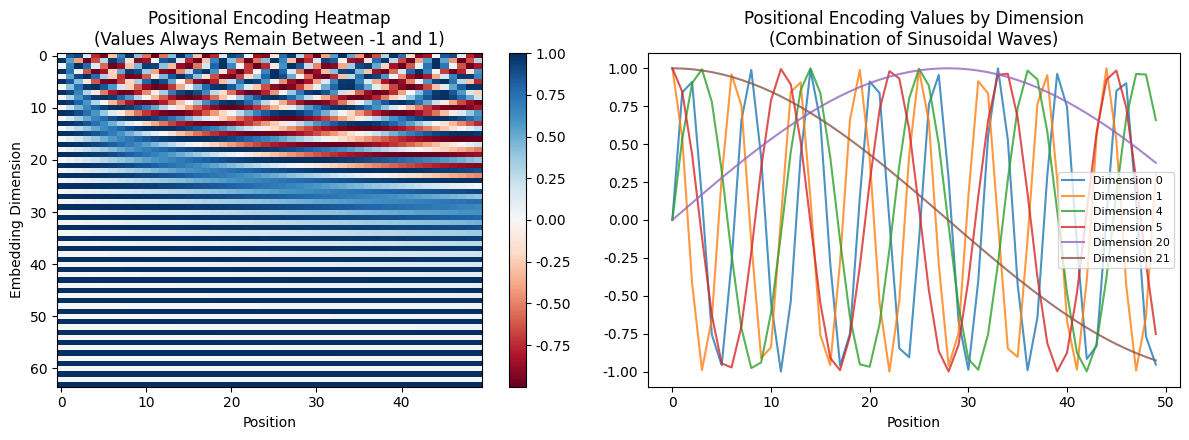

Positional Encoding shape: (50, 64)
값의 범위: [-1.000, 1.000]  <- 문장이 아무리 길어도 항상 이 범위 안에 있습니다.


In [32]:
def positional_encoding(seq_len, d_model):
    pos = np.arange(seq_len)[:, None]        # (seq_len, 1) 단어의 위치
    i = np.arange(d_model)[None, :]          # (1, d_model) 벡터의 차원 인덱스

    angle_rates = 1 / np.power(
        10000,
        (2 * (i // 2)) / np.float32(d_model)
    )
    angle_rads = pos * angle_rates

    pe = np.zeros((seq_len, d_model))
    pe[:, 0::2] = np.sin(angle_rads[:, 0::2])  # 짝수 차원 -> sin
    pe[:, 1::2] = np.cos(angle_rads[:, 1::2])  # 홀수 차원 -> cos
    return pe


pe = positional_encoding(seq_len=50, d_model=64)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

im = axes[0].imshow(pe.T, cmap='RdBu', aspect='auto')
axes[0].set_xlabel('Position')
axes[0].set_ylabel('Embedding Dimension')
axes[0].set_title(
    'Positional Encoding Heatmap\n'
    '(Values Always Remain Between -1 and 1)'
)
plt.colorbar(im, ax=axes[0])

for dim in [0, 1, 4, 5, 20, 21]:
    axes[1].plot(
        pe[:, dim],
        label=f'Dimension {dim}',
        alpha=0.8
    )

axes[1].set_xlabel('Position')
axes[1].set_title(
    'Positional Encoding Values by Dimension\n'
    '(Combination of Sinusoidal Waves)'
)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"Positional Encoding shape: {pe.shape}")
print(f"값의 범위: [{pe.min():.3f}, {pe.max():.3f}]  <- 문장이 아무리 길어도 항상 이 범위 안에 있습니다.")

**직접 해보기** `d_model` 값을 16, 128 등으로 바꿔보면서 히트맵의 줄무늬 패턴이
어떻게 달라지는지 관찰해보세요. (저차원은 빠르게, 고차원은 느리게 진동합니다)


---
# Part 5. Causal Masking — GPT처럼 미래를 못 보게 만들기

슬라이드의 "Fog of War Matrix"를 직접 구현합니다. GPT 같은 디코더는 다음 단어를
예측할 때, **아직 생성하지 않은 미래의 단어를 몰래 봐서는 안 됩니다.**
이를 위해 attention score 행렬에서 미래에 해당하는 부분을 `-∞`로 만들어버립니다.


Causal Mask (1=볼 수 있음, 0=가려짐):
[[1 0 0 0 0]
 [1 1 0 0 0]
 [1 1 1 0 0]
 [1 1 1 1 0]
 [1 1 1 1 1]]


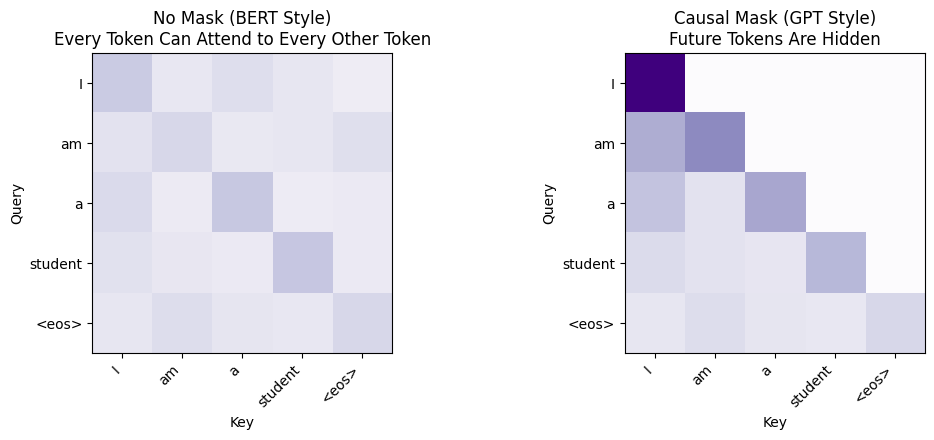

 오른쪽 그림에서 오른쪽 위(미래 단어) 부분이 전부 0(검정에 가까움)인 것을 확인하세요.
   'am'이 'a', 'student'를 미리 훔쳐보지 못하게 원천 차단된 것입니다.


In [33]:
sentence_tokens = ["I", "am", "a", "student", "<eos>"]
n = len(sentence_tokens)

# 1. 마스크 없는 경우 (모든 단어가 서로를 다 봄 - BERT 같은 인코더 방식)
np.random.seed(3)
emb = np.random.randn(n, 6) * 0.5
Q, K, V = emb, emb, emb  # 간단히 하기 위해 Q=K=V=embedding 사용

_, weights_no_mask = scaled_dot_product_attention(Q, K, V)

# 2. Causal mask 생성: 하삼각행렬(lower triangular) - 자기 자신과 이전 단어만 볼 수 있음
causal_mask = np.tril(np.ones((n, n)))
print("Causal Mask (1=볼 수 있음, 0=가려짐):")
print(causal_mask.astype(int))

_, weights_causal = scaled_dot_product_attention(Q, K, V, mask=causal_mask)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

titles = [
    'No Mask (BERT Style)\nEvery Token Can Attend to Every Other Token',
    'Causal Mask (GPT Style)\nFuture Tokens Are Hidden'
]

for ax, w, title in zip(
    axes,
    [weights_no_mask, weights_causal],
    titles
):
    im = ax.imshow(w, cmap='Purples', vmin=0, vmax=1)

    ax.set_xticks(range(n))
    ax.set_xticklabels(sentence_tokens, rotation=45, ha='right')

    ax.set_yticks(range(n))
    ax.set_yticklabels(sentence_tokens)

    ax.set_xlabel('Key')
    ax.set_ylabel('Query')
    ax.set_title(title)

plt.tight_layout()
plt.show()

print(" 오른쪽 그림에서 오른쪽 위(미래 단어) 부분이 전부 0(검정에 가까움)인 것을 확인하세요.")
print("   'am'이 'a', 'student'를 미리 훔쳐보지 못하게 원천 차단된 것입니다.")

---
# Part 6. 미니 트랜스포머 블록 조립하기

슬라이드 49의 트랜스포머 아키텍처 그림 중, **인코더 블록 하나**를 그대로 조립해봅니다.

```
입력 → [Multi-Head Attention] → Add & Norm → [Feed Forward] → Add & Norm → 출력
         ↑______________________|                ↑______________________|
              (잔차 연결, Residual Connection)
```

잔차 연결(Residual)과 층 정규화(LayerNorm)까지 포함한 완전한 블록입니다.


In [34]:
def layer_norm(x, eps=1e-6):
    # 각 토큰 벡터를 평균 0, 표준편차 1로 정규화 (학습을 안정시켜주는 장치)
    mean = x.mean(axis=-1, keepdims=True)
    std = x.std(axis=-1, keepdims=True)
    return (x - mean) / (std + eps)


def feed_forward(x, d_ff=32, seed=0):
    # 각 토큰마다 독립적으로 적용되는 작은 2층 신경망 (D -> d_ff -> D)
    rng = np.random.default_rng(seed)
    d_model = x.shape[-1]
    W1 = rng.normal(0, 0.1, (d_model, d_ff))
    W2 = rng.normal(0, 0.1, (d_ff, d_model))
    hidden = np.maximum(0, x @ W1)  # ReLU 활성화 함수
    return hidden @ W2


def transformer_encoder_block(X, num_heads, d_model, seed=0):
    # 1) Multi-Head Self-Attention
    attn_out, attn_weights = multi_head_attention(X, num_heads, d_model, seed=seed)

    # 2) 잔차 연결(Residual) + 층 정규화(LayerNorm)
    X = layer_norm(X + attn_out)

    # 3) Feed Forward Network
    ffn_out = feed_forward(X, seed=seed + 1)

    # 4) 다시 잔차 연결 + 층 정규화
    X = layer_norm(X + ffn_out)

    return X, attn_weights


In [35]:
output, attn_weights = transformer_encoder_block(embeddings, num_heads=3, d_model=d_model, seed=10)

print(f"입력 문장 토큰: {tokens}")
print(f"입력 shape: {embeddings.shape}  →  트랜스포머 블록 통과 후 shape: {output.shape}")
print("\n입력 벡터 (일부):")
print(np.round(embeddings[:2], 3))
print("\n트랜스포머 블록을 통과한 출력 벡터 (일부):")
print(np.round(output[:2], 3))
print("\n shape은 그대로(seq_len x d_model) 유지되지만, 값은 완전히 달라졌습니다.")
print("   각 단어의 벡터가 이제 '문장 전체 문맥을 반영한' 새로운 벡터로 바뀐 것입니다.")
print("   실제 LLM은 이 블록을 수십~수백 개 쌓아서(x N) 점점 더 깊은 문맥 이해를 만들어냅니다.")


입력 문장 토큰: ['그', '동물은', '길을', '건너지', '않았다', '그것은', '피곤했다']
입력 shape: (7, 6)  →  트랜스포머 블록 통과 후 shape: (7, 6)

입력 벡터 (일부):
[[ 0.845 -0.233  0.016  0.204 -0.394  0.001]
 [-0.    -0.877  0.509  0.3   -0.313 -0.086]]

트랜스포머 블록을 통과한 출력 벡터 (일부):
[[ 1.982 -0.795 -0.151  0.325 -1.118 -0.243]
 [ 0.231 -1.772  1.369  0.835 -0.415 -0.248]]

 shape은 그대로(seq_len x d_model) 유지되지만, 값은 완전히 달라졌습니다.
   각 단어의 벡터가 이제 '문장 전체 문맥을 반영한' 새로운 벡터로 바뀐 것입니다.
   실제 LLM은 이 블록을 수십~수백 개 쌓아서(x N) 점점 더 깊은 문맥 이해를 만들어냅니다.


---
# Part 7. 서브워드 토크나이저 미니 구현 (BPE)

슬라이드에서 본 BERT의 WordPiece처럼, 실제 LLM은 단어를 통째로 쓰지 않고
**자주 등장하는 문자 조각(subword)** 단위로 쪼갭니다. ("playing" → "play" + "##ing")

가장 널리 쓰이는 BPE(Byte Pair Encoding) 알고리즘을 미니 버전으로 직접 구현해봅니다.


In [36]:
import re
from collections import Counter, defaultdict

def get_vocab(corpus):
    # 단어를 '글자 단위 + 끝 표시(</w>)'로 쪼갠 초기 어휘집 생성
    vocab = Counter()
    for word in corpus.split():
        vocab[' '.join(list(word)) + ' </w>'] += 1
    return vocab

def get_pairs(vocab):
    # 현재 어휘집에서 서로 인접한 (글자, 글자) 쌍의 등장 빈도를 센다
    pairs = defaultdict(int)
    for word, freq in vocab.items():
        symbols = word.split()
        for i in range(len(symbols) - 1):
            pairs[(symbols[i], symbols[i+1])] += freq
    return pairs

def merge_vocab(pair, vocab):
    # 가장 빈도가 높은 쌍을 하나의 토큰으로 합친다
    new_vocab = {}
    bigram = re.escape(' '.join(pair))
    pattern = re.compile(r'(?<!\S)' + bigram + r'(?!\S)')
    for word in vocab:
        new_word = pattern.sub(''.join(pair), word)
        new_vocab[new_word] = vocab[word]
    return new_vocab


In [37]:
corpus = "low lower lowest newer new wider widest"
vocab = get_vocab(corpus)
print("Step 0 (초기: 모든 단어를 글자 단위로 분해):")
for w, f in vocab.items():
    print(f"  '{w}'  (빈도 {f})")

num_merges = 6
for step in range(num_merges):
    pairs = get_pairs(vocab)
    if not pairs:
        break
    best_pair = max(pairs, key=pairs.get)
    vocab = merge_vocab(best_pair, vocab)
    print(f"\nStep {step+1}: 가장 자주 붙어다니는 조각 {best_pair} 를 하나로 병합!")
    for w, f in vocab.items():
        print(f"  '{w}'")


Step 0 (초기: 모든 단어를 글자 단위로 분해):
  'l o w </w>'  (빈도 1)
  'l o w e r </w>'  (빈도 1)
  'l o w e s t </w>'  (빈도 1)
  'n e w e r </w>'  (빈도 1)
  'n e w </w>'  (빈도 1)
  'w i d e r </w>'  (빈도 1)
  'w i d e s t </w>'  (빈도 1)

Step 1: 가장 자주 붙어다니는 조각 ('l', 'o') 를 하나로 병합!
  'lo w </w>'
  'lo w e r </w>'
  'lo w e s t </w>'
  'n e w e r </w>'
  'n e w </w>'
  'w i d e r </w>'
  'w i d e s t </w>'

Step 2: 가장 자주 붙어다니는 조각 ('lo', 'w') 를 하나로 병합!
  'low </w>'
  'low e r </w>'
  'low e s t </w>'
  'n e w e r </w>'
  'n e w </w>'
  'w i d e r </w>'
  'w i d e s t </w>'

Step 3: 가장 자주 붙어다니는 조각 ('e', 'r') 를 하나로 병합!
  'low </w>'
  'low er </w>'
  'low e s t </w>'
  'n e w er </w>'
  'n e w </w>'
  'w i d er </w>'
  'w i d e s t </w>'

Step 4: 가장 자주 붙어다니는 조각 ('er', '</w>') 를 하나로 병합!
  'low </w>'
  'low er</w>'
  'low e s t </w>'
  'n e w er</w>'
  'n e w </w>'
  'w i d er</w>'
  'w i d e s t </w>'

Step 5: 가장 자주 붙어다니는 조각 ('e', 's') 를 하나로 병합!
  'low </w>'
  'low er</w>'
  'low es t </w>'
  'n e w er</w>'
  'n 

**관찰 포인트** `low`, `lower`, `lowest`가 공통으로 가진 `low`라는 조각이
자연스럽게 하나의 토큰으로 뭉쳐지는 것을 확인하세요. 이런 식으로 BPE는
**말뭉치에 자주 등장하는 패턴을 통계적으로 찾아서** 서브워드 단위를 만들어냅니다.
이렇게 만들어진 서브워드들이 실제 LLM 입력의 최소 단위(토큰)가 됩니다.


---
# Part 8. Vision Transformer — 이미지를 "문장"으로 바꾸기

슬라이드에서 본 것처럼, ViT의 핵심 아이디어는
**이미지를 작은 패치로 잘라서, 각 패치를 하나의 '단어(토큰)'처럼 취급한다**는 것입니다.
그러면 앞에서 만든 Self-Attention을 이미지에도 그대로 적용할 수 있습니다.


원본 이미지 크기: (8, 8)
패치 크기: 2x2 → 패치 개수: 16개, 패치 하나의 차원: 4
 8x8 이미지가 '16개의 단어로 이루어진 문장'으로 바뀌었습니다!


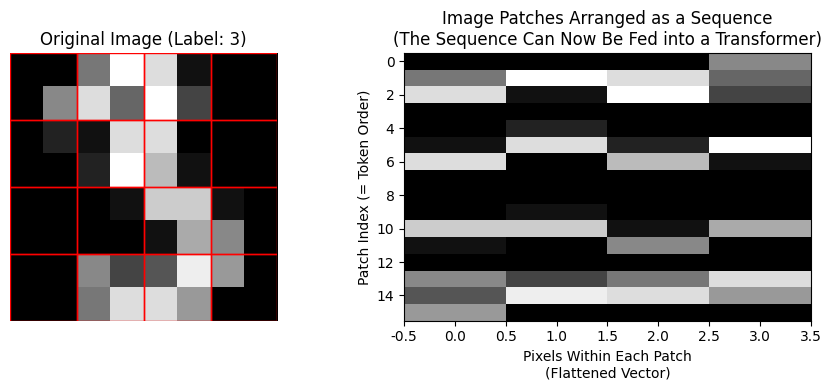

In [39]:
from sklearn.datasets import load_digits

digits = load_digits()
img = digits.images[3]  # 8x8 손글씨 숫자 이미지 (원하는 인덱스로 바꿔도 됩니다)

def patchify(img, patch_size=2):
    # 이미지를 patch_size x patch_size 크기의 작은 조각들로 잘라 1차원 벡터로 펼친다
    h, w = img.shape
    patches = []
    positions = []

    for i in range(0, h, patch_size):
        for j in range(0, w, patch_size):
            patch = img[i:i + patch_size, j:j + patch_size].flatten()
            patches.append(patch)
            positions.append((i, j))

    return np.array(patches), positions

patch_size = 2
patches, positions = patchify(img, patch_size=patch_size)

print(f"원본 이미지 크기: {img.shape}")
print(f"패치 크기: {patch_size}x{patch_size} → 패치 개수: {patches.shape[0]}개, 패치 하나의 차원: {patches.shape[1]}")
print(" 8x8 이미지가 '16개의 단어로 이루어진 문장'으로 바뀌었습니다!")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(img, cmap='gray')
axes[0].set_title(f'Original Image (Label: {digits.target[3]})')

for i, j in positions:
    axes[0].add_patch(
        plt.Rectangle(
            (j - 0.5, i - 0.5),
            patch_size,
            patch_size,
            fill=False,
            edgecolor='red',
            linewidth=1
        )
    )

axes[0].axis('off')

axes[1].imshow(patches, cmap='gray', aspect='auto')
axes[1].set_xlabel('Pixels Within Each Patch\n(Flattened Vector)')
axes[1].set_ylabel('Patch Index (= Token Order)')
axes[1].set_title(
    'Image Patches Arranged as a Sequence\n'
    '(The Sequence Can Now Be Fed into a Transformer)'
)

plt.tight_layout()
plt.show()

패치 시퀀스 입력 shape: (16, 4)  →  트랜스포머 통과 후 shape: (16, 4)
 각 이미지 패치가 이제 '다른 패치들과의 관계(문맥)'를 반영한 벡터로 바뀌었습니다.
   실제 ViT는 여기에 [CLS] 토큰을 추가하고 여러 블록을 쌓은 뒤, 그 [CLS] 벡터로 이미지를 분류합니다.


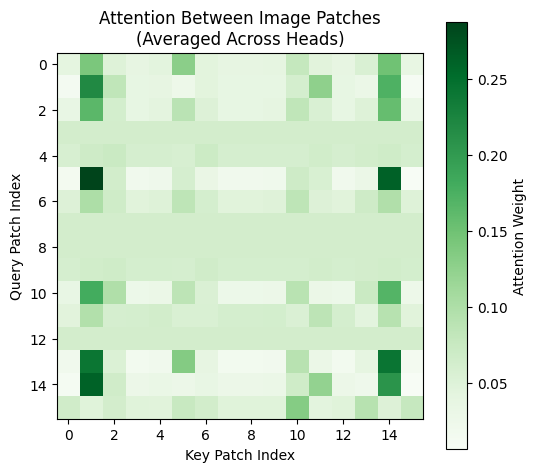

In [41]:
# 이제 이 패치 시퀀스를 Part 6에서 만든 트랜스포머 블록에 그대로 통과시켜봅니다!
# 패치 차원(4)을 d_model로 사용
d_model_vit = patches.shape[1]
num_heads_vit = 2  # d_model_vit(4)가 num_heads로 나누어 떨어져야 함

vit_output, vit_attn = transformer_encoder_block(
    patches.astype(float),
    num_heads=num_heads_vit,
    d_model=d_model_vit,
    seed=5
)

print(f"패치 시퀀스 입력 shape: {patches.shape}  →  트랜스포머 통과 후 shape: {vit_output.shape}")
print(" 각 이미지 패치가 이제 '다른 패치들과의 관계(문맥)'를 반영한 벡터로 바뀌었습니다.")
print("   실제 ViT는 여기에 [CLS] 토큰을 추가하고 여러 블록을 쌓은 뒤, 그 [CLS] 벡터로 이미지를 분류합니다.")

# 패치 간 attention 시각화: 어떤 패치가 어떤 패치에 주목하는지
avg_attn = vit_attn.mean(axis=0)  # head 평균

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(avg_attn, cmap='Greens')

ax.set_xlabel('Key Patch Index')
ax.set_ylabel('Query Patch Index')
ax.set_title('Attention Between Image Patches\n(Averaged Across Heads)')

plt.colorbar(im, ax=ax, label='Attention Weight')
plt.tight_layout()
plt.show()